In [1]:
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import SVG, display
import json
from collections import defaultdict

In [2]:
filepath = "feature_attribution_out/test_mutag_subgraphx_100_feat-attr.csv"
df = pd.read_csv(filepath, header = 0)
df.head()

,Drug,Drug_ID,Y,aromatic amine,three-membered heterocycle,unsubstituted heteroatom-bonded heteroatom,azo-type,aliphatic halide,specific arom amine,alkyl nitrite,epoxide,aziridine,azide,diazo,triazene,aromatic azo,aromatic hydroxylamine,carboxylic acid halide,Top Substructure
0,OC(=O)c1cc(cc2cccnc12)[N+](=O)[O-],70585-52-3,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,c[N+].ccc
1,CC1C2C3C(C)C4C(=O)C56C(=O)c7c(O)cc(C)cc7C(=O)C...,67278-88-0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,CCCC
2,C1CCC(CC1)N2C3C2c4ccccc4c5ccccc35,64188-65-4,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,cc-cc
3,CCOC(=O)C(C)Br,535-11-5,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,COCCBr
4,Nc1ccc(Oc2cccc(Oc3ccc(N)cc3)c2)cc1,2479-46-1,1,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,cO.cOc


In [ ]:
# get substructure count (for positive samples)
df_pos = df[df["Y"] == 1]
top_counts = df_pos["Top Substructure"].value_counts()
print(type(top_counts))

Top Substructure
ccN=Nc           4
ccccc            4
c[N+].ccc        2
CCCCC            2
C=Ccoc           2
cccc             2
ccc(c)c          2
ccc(c)[N+]       2
ccccN            2
CNCN[N+]         1
cc(-c)cC         1
c/C=C/CN         1
NCCCO            1
N=cccn           1
cc-ccC           1
cNC.cO           1
cc([N+])c[N+]    1
ccccn            1
cc(c)CC          1
C1CCNC1          1
CCnc[N+]         1
cCc              1
cnc(n)N          1
cN.cc-c          1
CCNC             1
cCNc             1
cccc[N+]         1
c-c.cn           1
cc[N+]=Nc        1
c/C=N/NC         1
c[N+].ccN        1
c/C=C/C=N        1
C=C(C)CC         1
cCONC            1
cO.cOc           1
ccccC            1
cN.cc[N+]        1
CCCC             1
cc(-c)c[N+]      1
CNcn             1
Cc[nH]c[N+]      1
CC=C(C)C         1
COCCBr           1
c-c.cc-c         1
cc(c)c[N+]       1
cccnc            1
cc-cc            1
ccc-c            1
cccCn            1
CCC(C)C          1
Name: count, dtype: int64

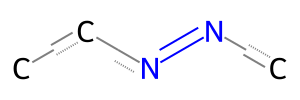

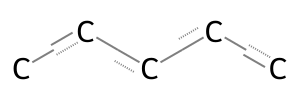

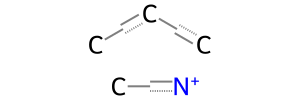

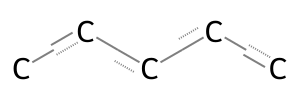

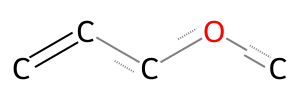

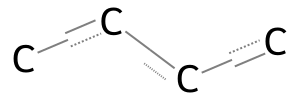

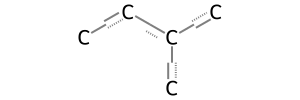

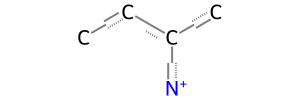

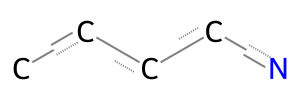

In [4]:
# visualise top substructures
idx = 0
for smarts, count in top_counts.items():
    idx += 1

    if count < 2:
        break

    mol = Chem.MolFromSmarts(smarts)

    # Set the atom label to 'C' for all carbon atoms
    for atom in mol.GetAtoms():
        if atom.GetSymbol() == 'C':
            atom.SetProp('atomLabel', 'C')

    drawer = Draw.rdMolDraw2D.MolDraw2DSVG(300, 100)

    dopts = drawer.drawOptions()
    dopts.bondLineWidth = 2.0         # Slightly thicker lines for clarity
    dopts.addAtomIndices = False      # Hide atom indices
    dopts.clearBackground = False     # Transparent background (useful for papers/slides)

    # 5. Draw molecule with highlights
    drawer.DrawMolecule(
        mol
    )
    drawer.FinishDrawing()

    svg_text = drawer.GetDrawingText()

    filename = f"molecule_substructure_images/top_substructures_100_nitro/{idx}_{smarts}.svg"
    with open(filename, 'w') as f:
        f.write(svg_text)

    display(SVG(svg_text))

    

## Reproduce with new SC architecture

In [5]:
filepath = "feature_attribution_out/test_mutag_subgraphx_feat-attr_nitro_new.csv"
df = pd.read_csv(filepath, header = 0)
df.head()

,Drug,Drug_ID,Y,aromatic amine,three-membered heterocycle,unsubstituted heteroatom-bonded heteroatom,azo-type,aliphatic halide,specific arom amine,alkyl nitrite,epoxide,aziridine,azide,diazo,triazene,aromatic azo,aromatic hydroxylamine,carboxylic acid halide,Top Substructure
0,C(=O)c1cc(cc2cccnc12)[N+](=O)[O-],70585-52-3,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,"Disconnected atom indices: [11, 1, 7, 14, 13]"
1,CC1C2C3C(C)C4C(=O)C56C(=O)c7c(O)cc(C)cc7C(=O)C...,67278-88-0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,"Disconnected atom indices: [0, 28, 11, 14, 17]"
2,C1CCC(CC1)N2C3C2c4ccccc4c5ccccc35,64188-65-4,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,CCCC
3,CCOC(=O)C(C)Br,535-11-5,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,CC(Br)C=O
4,Nc1ccc(Oc2cccc(Oc3ccc(N)cc3)c2)cc1,2479-46-1,1,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,cccN


In [ ]:
# get substructure count (for positive samples)
df_pos = df[df["Y"] == 1]
top_counts = df_pos["Top Substructure"].value_counts()
top_counts_clean = [idx for idx in top_counts.index if "Disconnected" not in idx]
top_counts

Top Substructure
c[N+](=O)[O-]                                     11
O=[N+][O-]                                         6
CC=O                                               2
cc                                                 2
CC(C)C                                             2
CO.O=[N+][O-]                                      2
ccc(c)Cl                                           2
CNC.CO                                             1
Disconnected atom indices: [0, 12, 2, 14, 15]      1
cc(N)[n+][O-]                                      1
Disconnected atom indices: [14, 10, 0, 8, 4]       1
CN=[N+]=[N-]                                       1
c[N+]=O                                            1
CC(=O)O                                            1
CC.CCBr                                            1
ccN                                                1
Disconnected atom indices: [0, 10, 8, 6, 13]       1
Disconnected atom indices: [2, 4, 0, 6, 8]         1
cN=O                         

: 

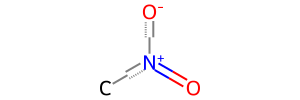

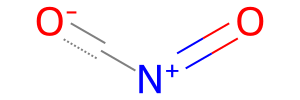

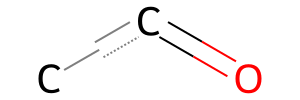

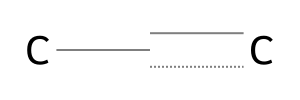

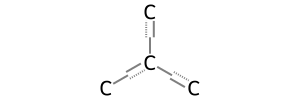

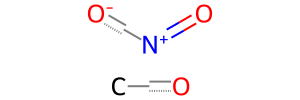

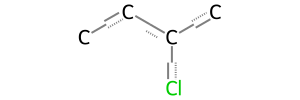

In [81]:
# visualise top substructures
idx = 0
for smarts, count in top_counts.items():
    idx += 1

    if count < 2:
        break

    mol = Chem.MolFromSmarts(smarts)

    # Set the atom label to 'C' for all carbon atoms
    for atom in mol.GetAtoms():
        if atom.GetSymbol() == 'C':
            atom.SetProp('atomLabel', 'C')

    drawer = Draw.rdMolDraw2D.MolDraw2DSVG(300, 100)

    dopts = drawer.drawOptions()
    dopts.bondLineWidth = 2.0         # Slightly thicker lines for clarity
    dopts.addAtomIndices = False      # Hide atom indices
    dopts.clearBackground = False     # Transparent background (useful for papers/slides)

    # 5. Draw molecule with highlights
    drawer.DrawMolecule(
        mol,
        #legend = f"{smarts} (# = {count})"
    )
    drawer.FinishDrawing()

    svg_text = drawer.GetDrawingText()

    filename = f"molecule_substructure_images/top_substructures_100_nitro_new/{idx}_{smarts}.svg"
    with open(filename, 'w') as f:
        f.write(svg_text)

    display(SVG(svg_text))


## Other selection strategies

In [ ]:
# only evaluate positive molecules with all positive concepts deleted
df_pos = df[df["Y"] == 1]
df_pos_no_concept = df_pos[df_pos.drop(columns = ["Drug_ID", "Drug", "Y", "Top Substructure"]).eq(0).all(axis = 1)]
df_pos_no_concept

,Drug,Drug_ID,Y,aromatic amine,three-membered heterocycle,unsubstituted heteroatom-bonded heteroatom,azo-type,aliphatic halide,specific arom amine,alkyl nitrite,epoxide,aziridine,azide,diazo,triazene,aromatic azo,aromatic hydroxylamine,carboxylic acid halide,Top Substructure
81,Cn1ccnc1N=O,116169-87-0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,cN=O


## Checking identified substructures against set of deleted concepts

In [57]:
deleted_nitro_file = "data/mutag_dataset_remove_nitro/substructures_removed.json"
with open(deleted_nitro_file, "r", encoding = "utf-8") as f:
    deleted_nitro = json.load(f)

present_nitro_file = "data/mutag_dataset_remove_nitro/substructures.json"
with open(present_nitro_file, "r", encoding = "utf-8") as f:
    present_nitro = json.load(f)

In [ ]:
def check_against_deleted(substructure: str, deleted_concepts: dict) -> list:

    deleted_concept_mols = {key : Chem.MolFromSmarts(val) for key, val in deleted_concepts.items()}
    substructure_mol = Chem.MolFromSmarts(substructure)

    matches = []
    for key, val in deleted_concept_mols.items():
        if substructure_mol.HasSubstructMatch(val, useQueryQueryMatches = True):
        #if substructure_mol.HasSubstructMatch(val):
            matches.append(key)

    return matches

matches_test = check_against_deleted("cN=O", deleted_nitro)
matches_test

['nitroso']

In [90]:
def check_all_substructures(top_substructures: list, deleted_concepts: dict) -> dict:

    matches_per_substruct = {}
    for s in top_substructures:
        if "Disconnected" in s:
            continue
        matches_per_substruct[s] = check_against_deleted(s, deleted_concepts)

    return matches_per_substruct

matches_per_substructure = check_all_substructures(top_counts.index.to_list(), present_nitro)

for key, val in matches_per_substructure.items():
    if val:
        print(key, val, sep = "\t")

ccc(c)Cl	['aliphatic halide']
CN=[N+]=[N-]	['azide']
CC.CCBr	['aliphatic halide']
C=C(Cl)Cl	['aliphatic halide']
CC(Br)C=O	['aliphatic halide']
CCCl.CO	['aliphatic halide']
CC(Cl)Br	['aliphatic halide']
